In [1]:
# %pip install langgraph
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/langchain_core/utils/pydantic.py:42: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1 import BaseModel as BaseModelV1


In [2]:
# define state
class SiState(TypedDict):

    principle: int
    rate: float
    time: int
    result: float
    state: str

In [3]:
def calculate_si(state: SiState) -> SiState:

    principle = state['principle']
    rate = state['rate']
    time = state['time']

    si = (principle * rate * time) / 1000

    state['result'] = round(si, 2)

    return state



In [4]:
def label_si(state: SiState) -> SiState:

    si = state['result']

    if si < 1000:
        state["status"] = "Bad"
    else:
        state["status"] = "Good"

    return state


In [5]:
# define your graph
graph = StateGraph(SiState)

# add nodes to your graph
graph.add_node('calculate_si', calculate_si)
graph.add_node('label_si', label_si)

# add edges to your graph
graph.add_edge(START, 'calculate_si')
graph.add_edge('calculate_si', 'label_si')
graph.add_edge('label_si', END)


# compile the graph
workflow = graph.compile()



In [6]:
# execute the graph
initial_state = {'principle':1000, 'rate':5, 'time':2}

final_state = workflow.invoke(initial_state)

print(final_state)

{'principle': 1000, 'rate': 5, 'time': 2, 'result': 10.0}


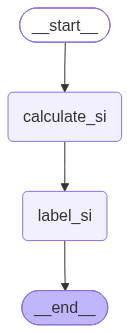

In [7]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())